# 1. LSO data and NRHO station-keeping identification

**Question:** Can an LSO-informed, phase-dependent model choose the impulse magnitude and orbital phase needed to keep a spacecraft within **10 km** in position and **0.1 m/s** in velocity of its nominal NRHO?

An NRHO is a repeating path near the Moon. An impulse is a short velocity change that corrects departure from that path. Three **lunar surface observatories (LSOs)** measure line-of-sight angles, not position or velocity directly. Their noisy angles and actual visibility gaps feed a state estimator. Simulation truth is reserved for generating sensors and evaluating accuracy.

Inputs are commanded impulses in three directions. Reconstructed outputs are position and inertial-velocity departures resolved along rotating Earth–Moon axes. Phase means time through the orbit in degrees, not a geometric angle. Measurements at epoch $k$ precede impulse $u_k$, which affects the next state.

LSO angle noise: 1 arcsec. Uniform cadence: 1.51 hour.


| Split | Independent trajectories | Seed range |
| --- | --- | --- |
| training | 8 | 6960–6967 |
| validation | 4 | 7960–7963 |
| test | 4 | 8960–8963 |

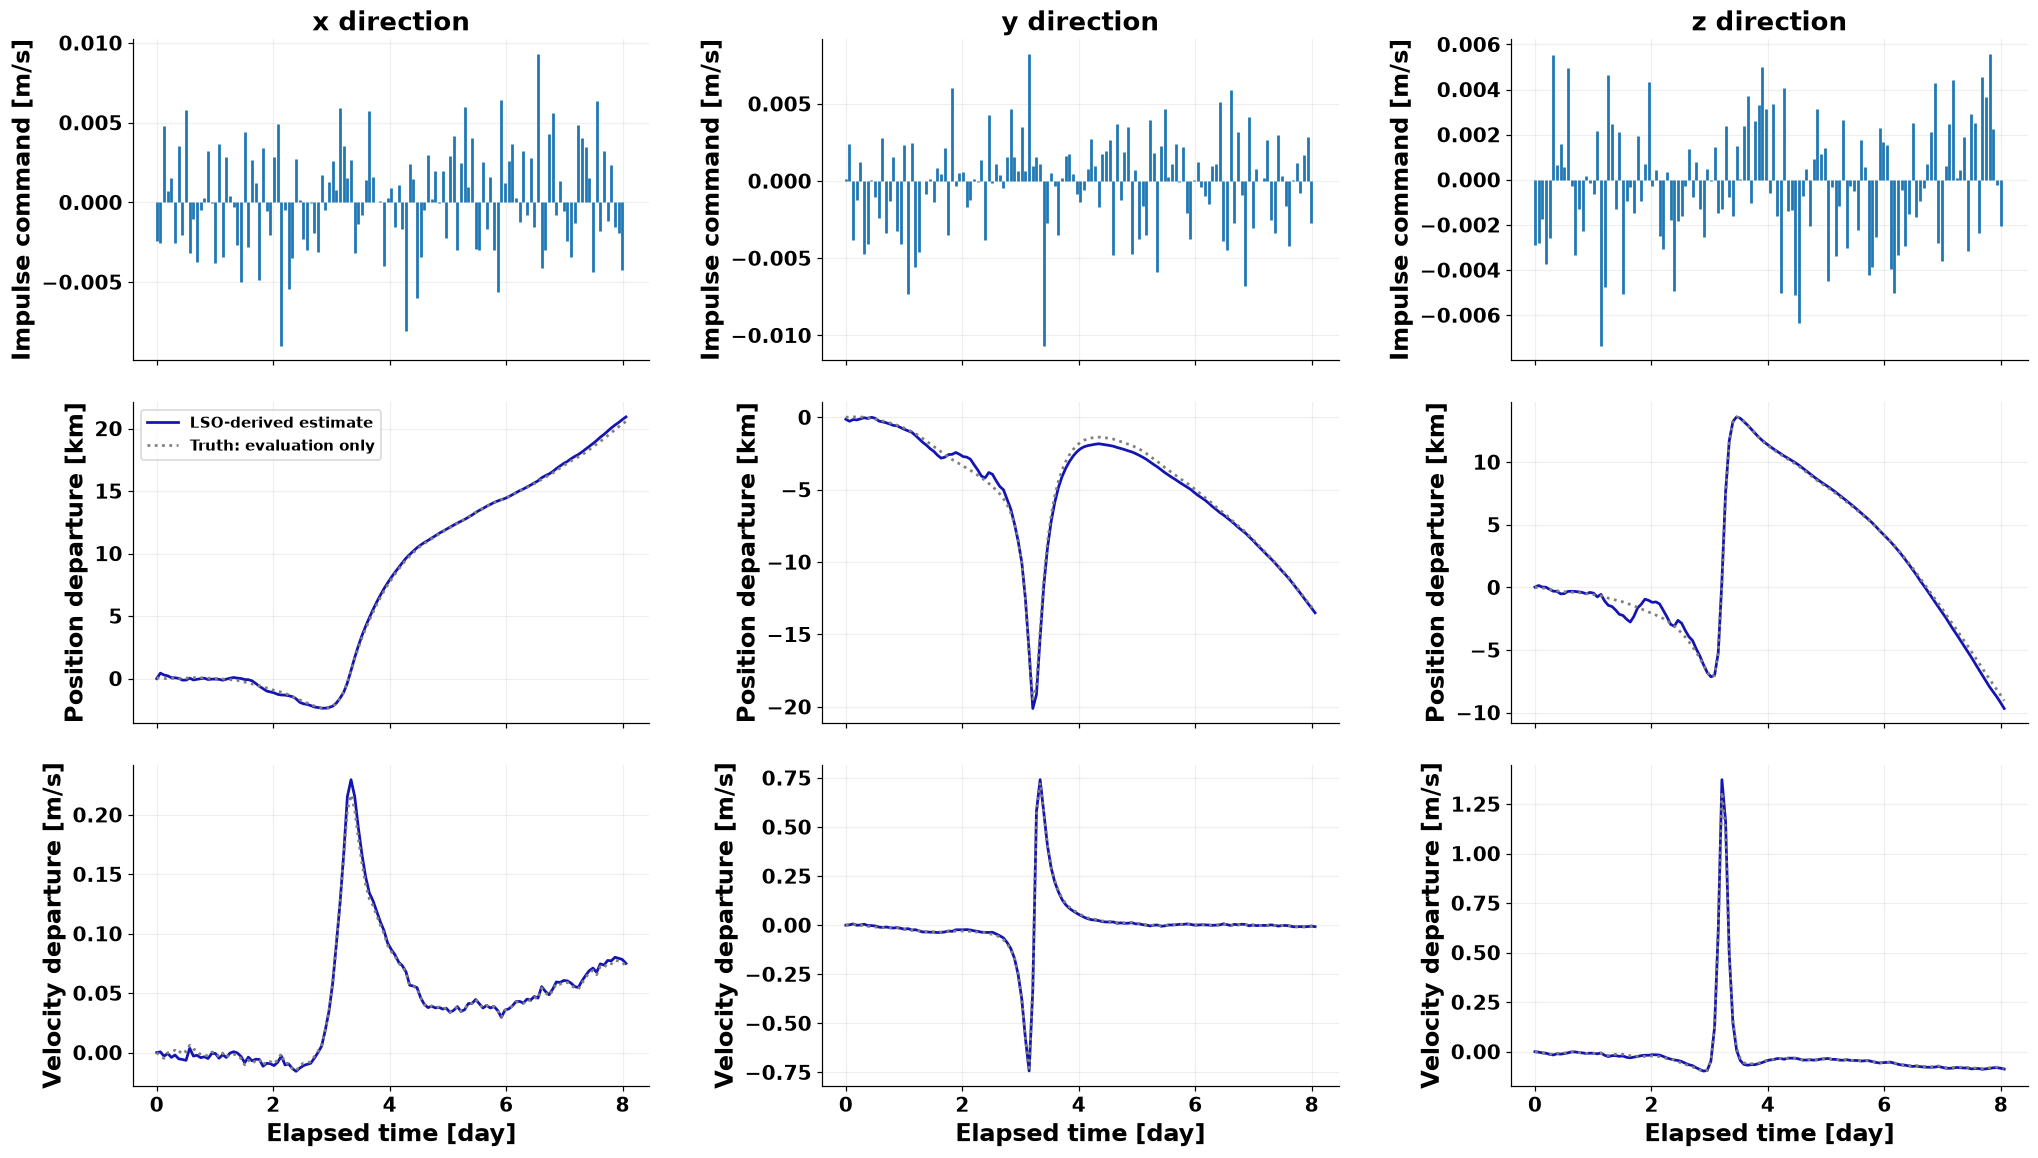

**Purpose:** These plots compare the three commanded impulses with the six departures reconstructed from LSO angles.

**Result:** The training navigation position RMSE is 0.427 km, showing the measurement-to-state uncertainty that the identification workflow must retain.

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown
from halo_tracking import stationkeeping as physics
from halo_tracking import lso_stationkeeping as sk
from halo_tracking import stationkeeping_diagnostics as sd
from halo_tracking import lso_diagnostics as ld
from halo_tracking import lso_report_plots as plots
ROOT=Path.cwd()
if not (ROOT/'configs').exists(): ROOT=ROOT.parent
OUT=ROOT/'artifacts'/'stationkeeping'
OUT.mkdir(parents=True,exist_ok=True)
plots.style()
def table(headers,rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

orbit,data=sk.prepare_study(ROOT,OUT/'data')
training=data['training']
table(['Split','Independent trajectories','Seed range'],[(n,len(r.seeds),f'{r.seeds[0]}–{r.seeds[-1]}') for n,r in data.items()])
print(f'LSO angle noise: {orbit.cfg["measurement"]["angle_sigma_arcsec"]:g} arcsec. Uniform cadence: {orbit.dt_s/3600:.2f} hour.')
plots.inputs_outputs(orbit,training,OUT/'figures')

## What is actually measured?

The LSO channels are inertial-axis angles $\alpha$ and $\delta$. Elevation, range and configured Sun/Earth exclusions determine availability. Missing angles remain blank, while a finite state estimate during an outage is a model prediction, not a new measurement. The block diagram separates this measurement path from the station-keeping feedback.

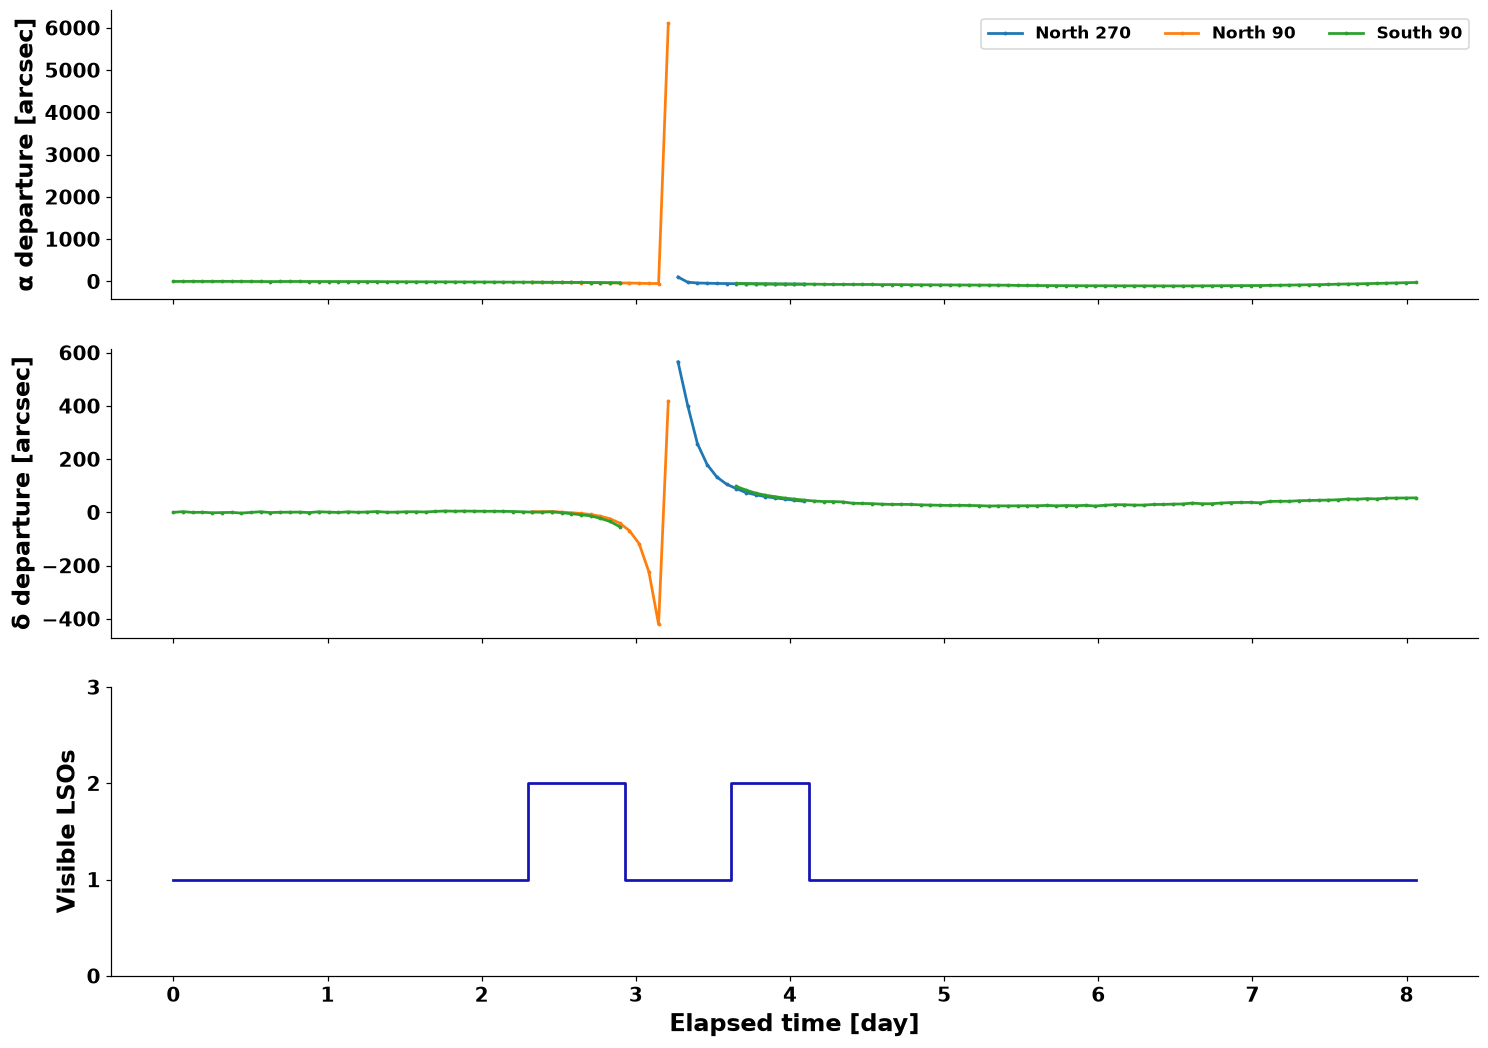

**Purpose:** The angular-departure plots show the actual noisy LSO data relative to the nominal line of sight, with missing samples left blank.

**Result:** At least one LSO is visible at 100.0% of training epochs, giving full network coverage in this case even though individual LSO channels are masked.

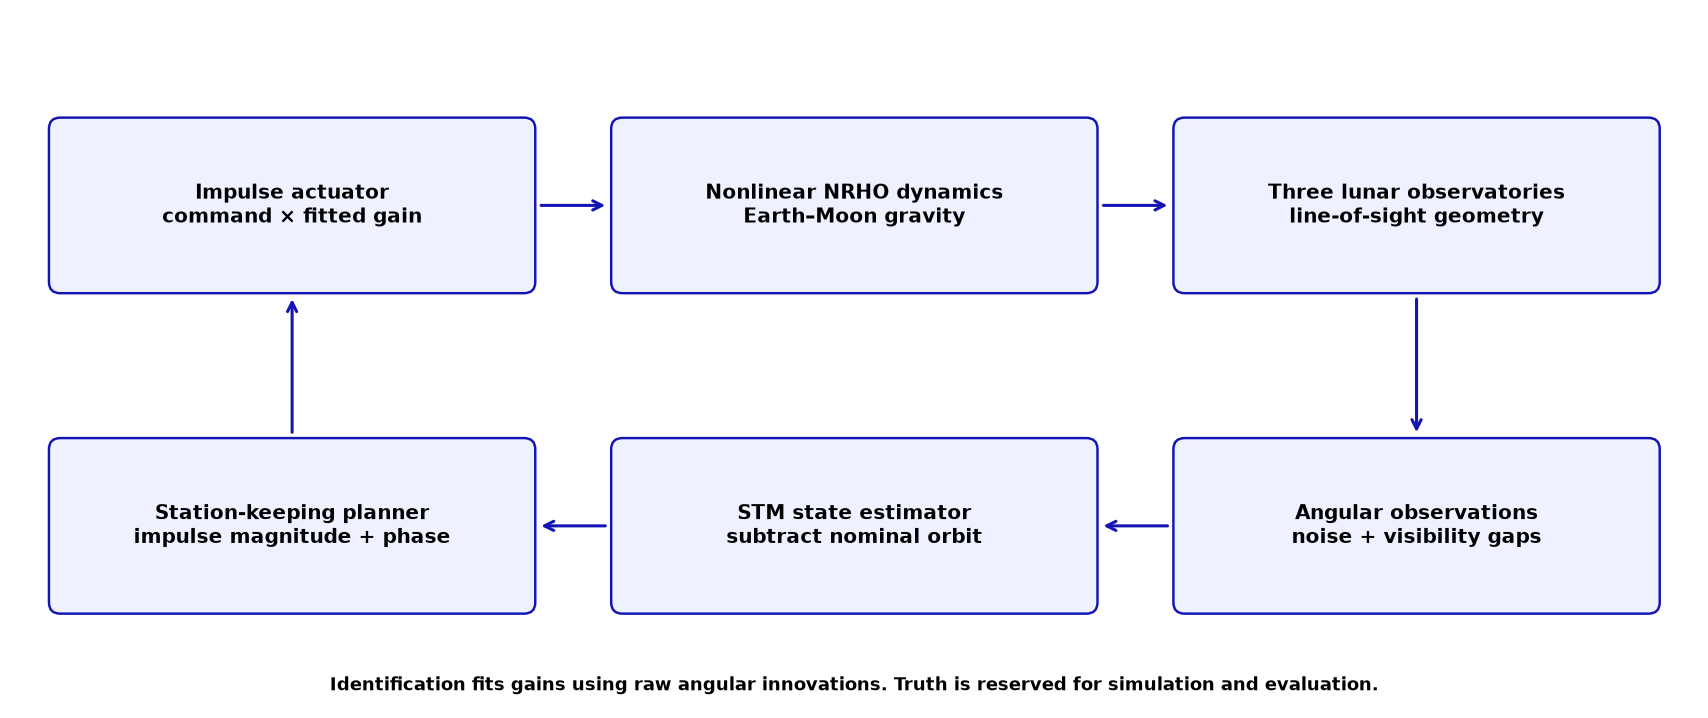

**Purpose:** This diagram identifies the measurement and feedback paths used to keep the NRHO near its nominal orbit.

**Result:** The 3 LSOs provide angles rather than direct position or velocity measurements, so visibility and state estimation are part of the station-keeping problem.

In [2]:
plots.lso_measurements(orbit,training,OUT/'figures')
plots.diagram(orbit,OUT/'figures')

## Welch spectra and empirical response

Following Studios 7–8, use Hann windows and 50% overlap, averaging within separate trajectories. The full MIMO estimate is $\hat H=\hat S_{yu}\hat S_{uu}^{-1}$ with cross-spectrum $Y U^*$. The displayed channels are its three direct position responses. Because $y$ is an **LSO-derived state estimate**, its response includes estimator dynamics and is not the physical plant transfer function alone.

Compare window lengths before interpreting peaks: quarter-orbit windows cannot resolve the orbital fundamental, while full-orbit windows leave one window per trajectory. These are finite-record summaries. A stationary output spectrum or global LTI transfer function is not assumed.

findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight bold for cmmi10, now using 400.
findfont: Failed to find font weight bold for cmsy10, now using 400.
findfont: Failed to find font weight bold for cmr10, now using 400.
findfont: Failed to find font weight bold for cmtt10, now using 400.
findfont: Failed to find font weight bold for cmti10, now using 400.
findfont: Failed to find font weight bold for cmb10, now using 400.
findfont: Failed to find font weight bold for cmss10, now using 400.
findfont: Failed to find font weight bold for cmex10, now using 400.
findfont: Failed to find font weight bold for DejaVu Sans Display, now using 400.


| Window length | Resolution [cycle/day] | Averaged windows |
| --- | --- | --- |
| 16 | 0.993 | 120 |
| 32 | 0.496 | 56 |
| 64 | 0.248 | 24 |
| 128 | 0.124 | 8 |

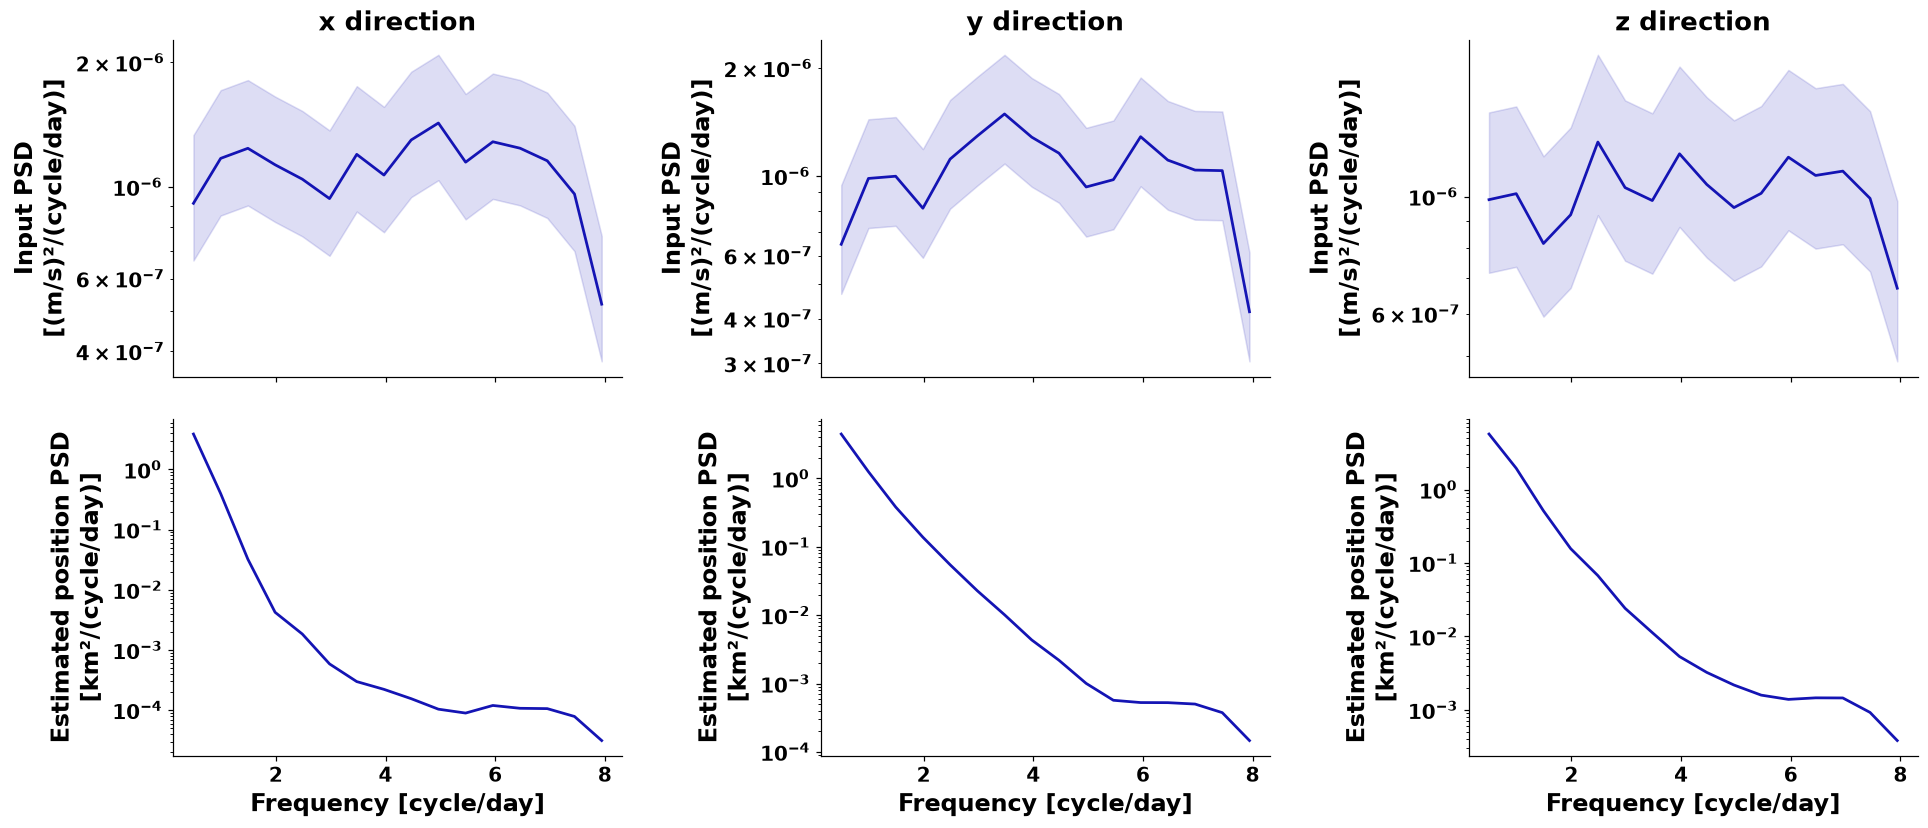

**Purpose:** Welch spectra compare input excitation with the frequency content of the LSO-derived position estimates.

**Result:** The chosen window gives 0.496 cycle/day resolution and 56 windows, so these curves summarize a filtered finite record rather than establish a stationary plant spectrum.

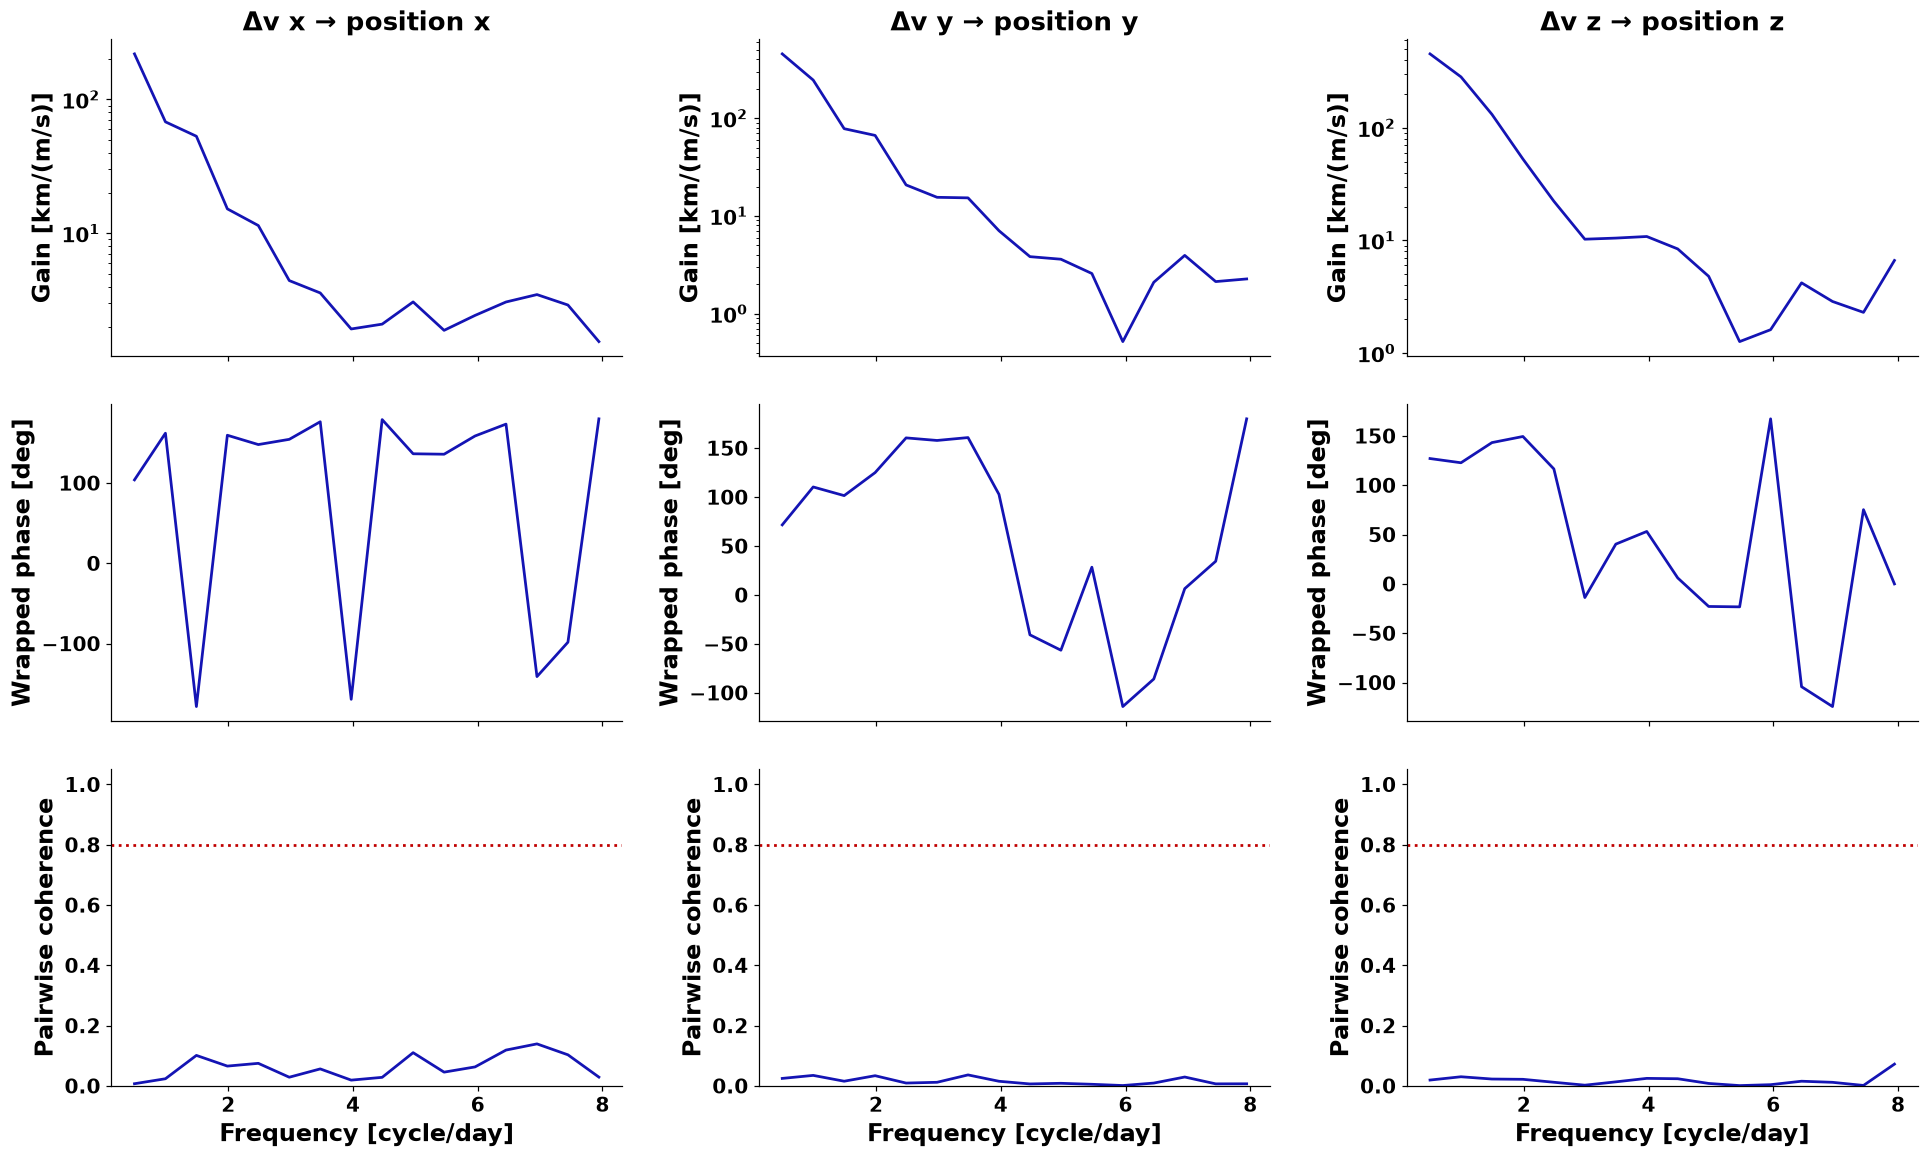

**Purpose:** The displayed diagonal channels of the full MIMO estimate show response gain, phase and input–output coherence.

**Result:** Only 0.0% of these bins meet the 0.8 coherence screen, and the response includes LSO estimation dynamics, so a global LTI plant model is not justified by this plot alone.

In [3]:
s=orbit.settings
spec=sd.welch_bundle(training.u,training.y[:,:-1],1/orbit.dt_s,s['welch_length'])
table(['Window length','Resolution [cycle/day]','Averaged windows'],[(L,f'{86400/(orbit.dt_s*L):.3g}',sd.welch_bundle(training.u,training.y[:,:-1],1/orbit.dt_s,L)['segments']) for L in (16,32,64,128)])
plots.spectra(orbit,spec,OUT/'figures')
plots.frf(spec,OUT/'figures')

## Stationarity and model structure

Studio 6 compares segment means/variances and pairs ADF (unit-root null) with KPSS (level-stationarity null). Here the reconstructed states include estimator dynamics. Angular gaps are never filled to manufacture measurements. The phase/linearity/Floquet plots then test whether a local time-invariant approximation is credible and whether perturbations grow over an orbit.

* KPSS table-bound warnings are retained in the saved report.


| Channel | ADF p | KPSS p* | Joint reading |
| --- | --- | --- | --- |
| r x | 0.948 | 0.01 | evidence against level stationarity |
| r y | 0.339 | 0.0101 | evidence against level stationarity |
| r z | 0.611 | 0.1 | inconclusive / low power |
| v x | 0.0433 | 0.0425 | conflicting tests |
| v y | 5.27e-06 | 0.1 | supports level stationarity |
| v z | 0.0032 | 0.1 | supports level stationarity |

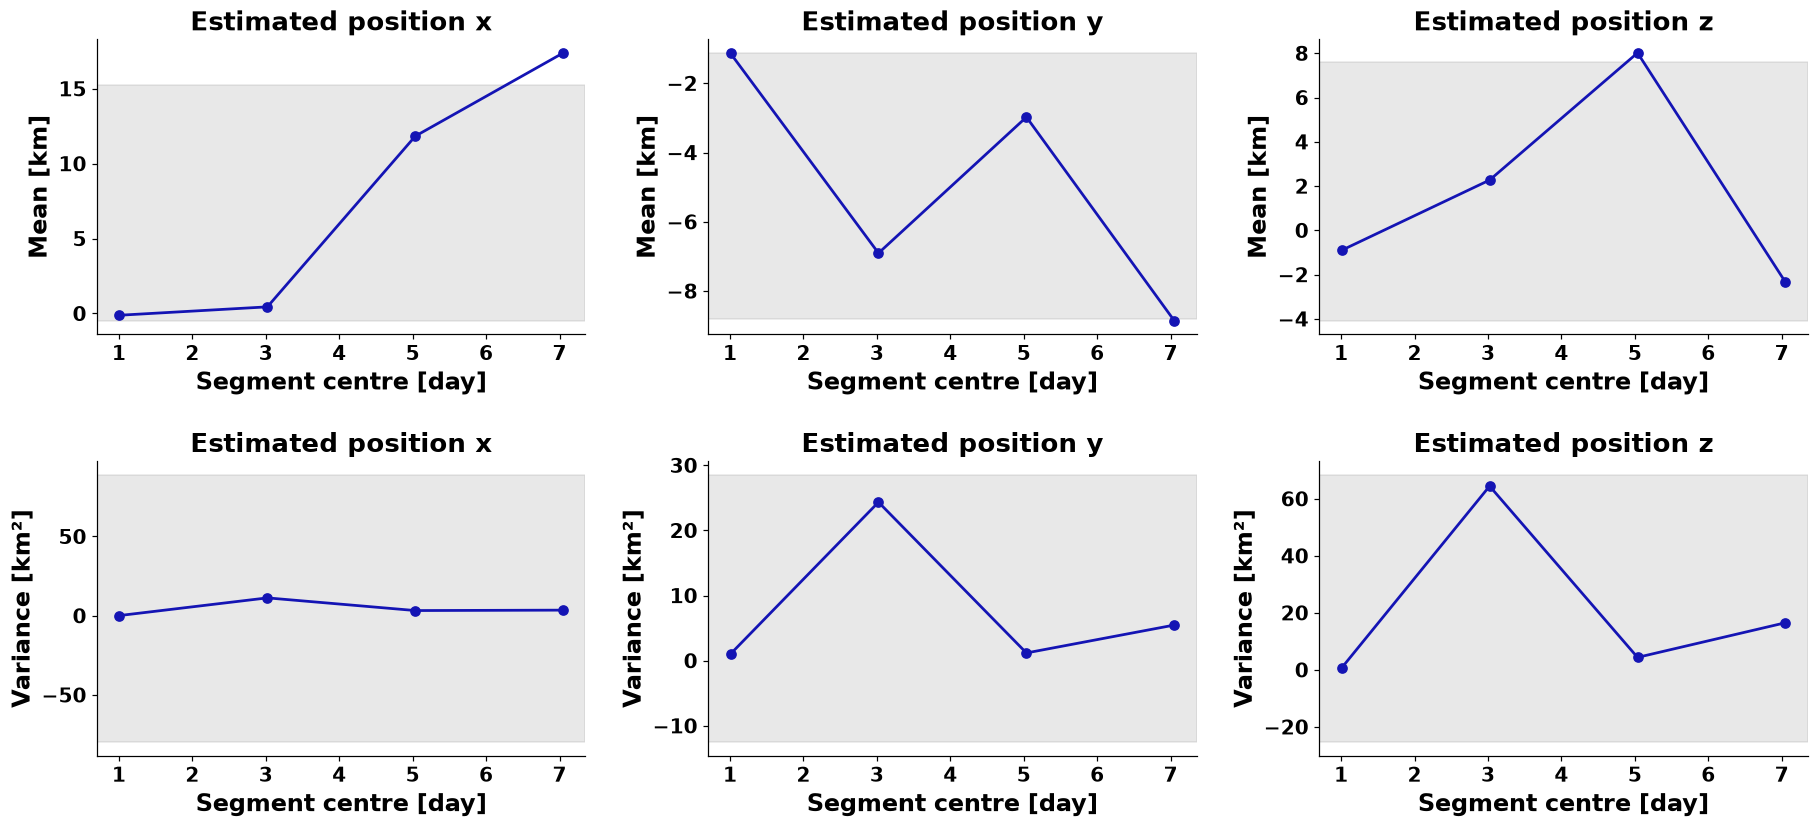

**Purpose:** Segment means and variances check whether the LSO-derived position record maintains comparable statistics over an orbit.

**Result:** The six state channels produce 12 mean/variance flags across their segment checks, so stationarity must be assessed with the accompanying ADF/KPSS results and visibility history rather than assumed.

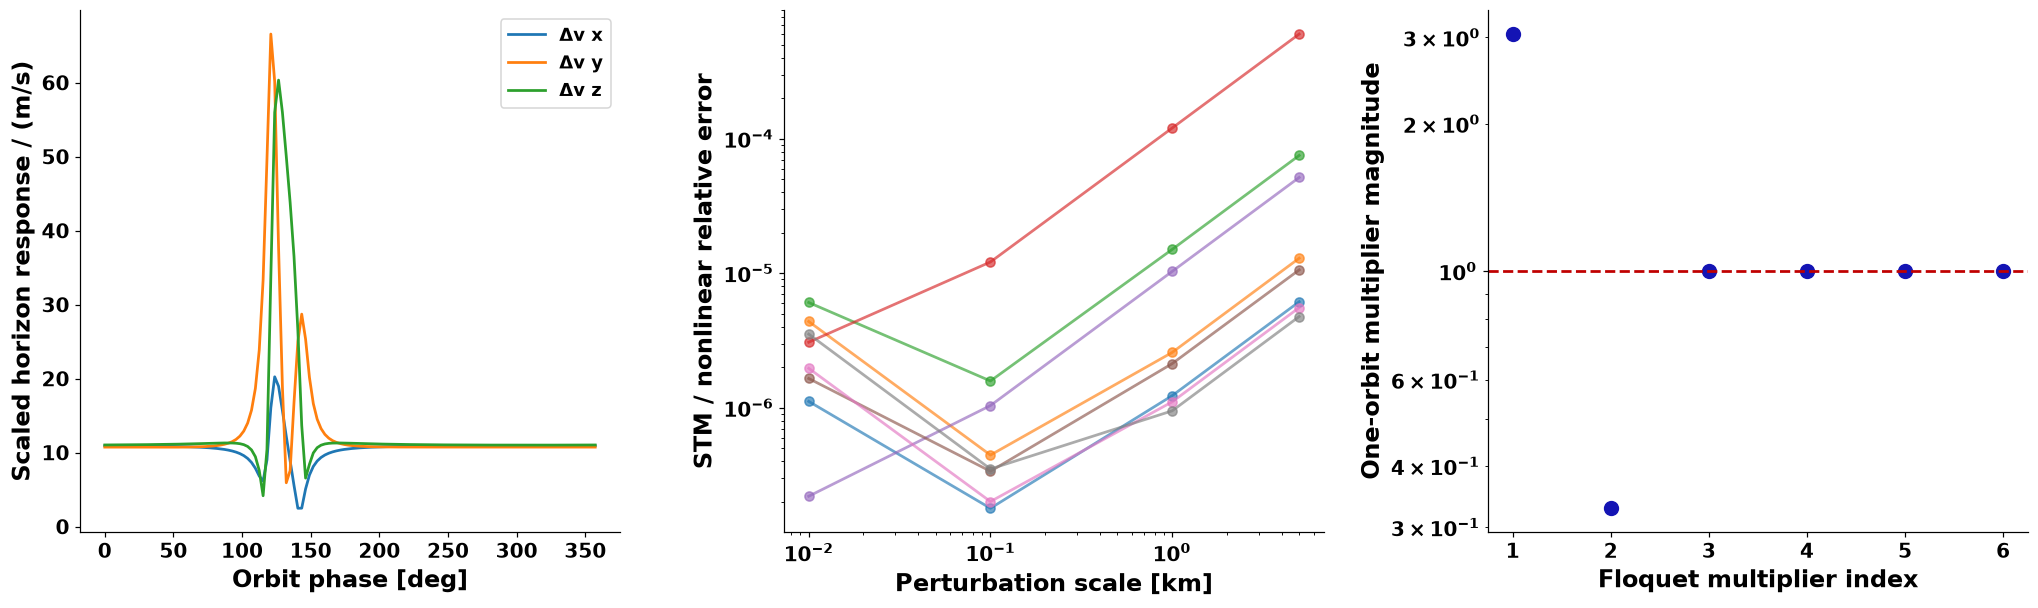

**Purpose:** These diagnostics separate phase-dependent sensitivity, finite-amplitude linearization error and one-orbit perturbation growth.

**Result:** Horizon sensitivity varies by a factor of 4.5 over phase and the largest multiplier is 3.05, supporting a time-varying local model with an unstable mode.

In [4]:
names=['r x','r y','r z','v x','v y','v z']
stationarity_rows=[sd.stationarity(training.y[0,:,c],names[c]) for c in range(6)]
table(['Channel','ADF p','KPSS p*','Joint reading'],[(r['channel'],f"{r['adf_p']:.3g}",f"{r['kpss_p']:.3g}",r['reading']) for r in stationarity_rows])
print('* KPSS table-bound warnings are retained in the saved report.')
(OUT/'stationarity.json').write_text(json.dumps(stationarity_rows,indent=2)+'\n')
plots.stationarity(orbit,training,stationarity_rows,OUT/'figures')
diagnostics=physics.finite_horizon_diagnostics(orbit)
plots.structure(diagnostics,OUT/'figures')
np.savez_compressed(OUT/'structure_diagnostics.npz',**diagnostics)

## Longer propagation shows uncontrolled growth

Propagate the same small initial departure continuously for **up to 24 orbits**, stopping at a declared 20,000 km departure cutoff or integration failure. Only the reference repeats. The spacecraft is never reset. Orthographic orbit projections replace the overlapping 3-D axes, alongside position and velocity growth panels.

Out[5]: 115


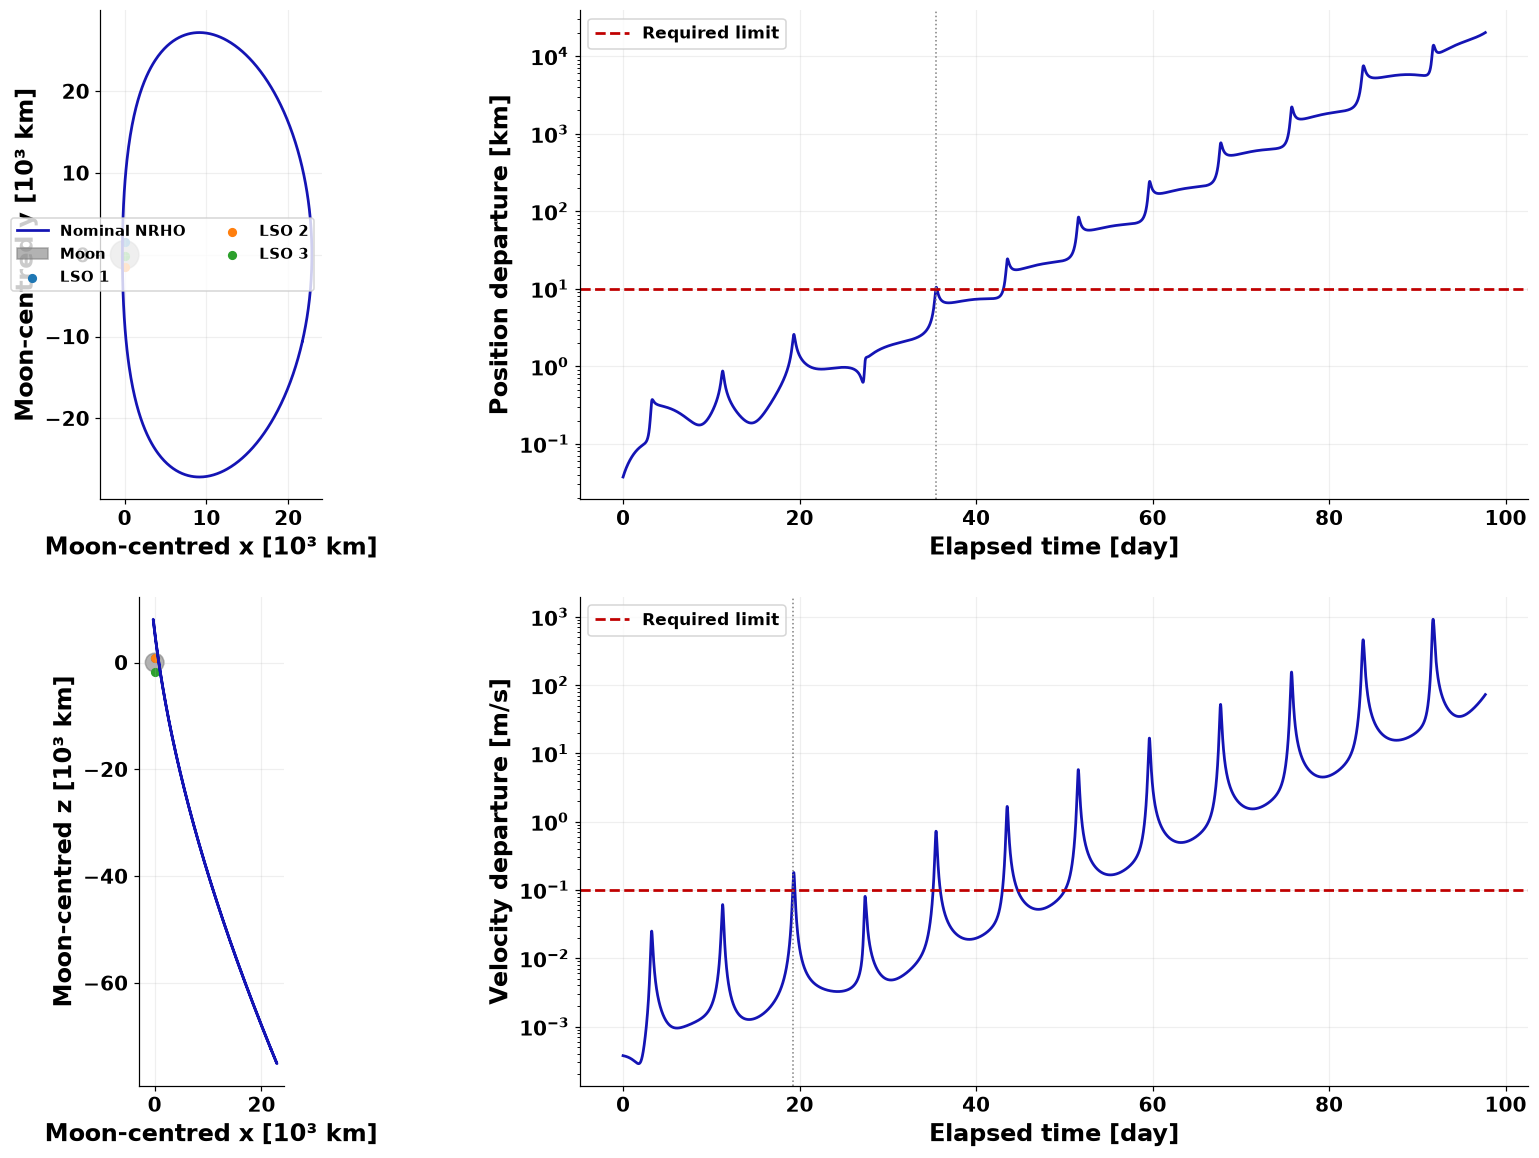

**Purpose:** Moon-centred orbit projections locate the LSOs, while a continuous unforced trajectory shows how a small initial departure grows over the extended propagation.

**Result:** By day 97.7, peak departures reach 2.02e+04 km and 922 m/s, with the declared stop condition recorded as “reached declared departure cutoff”.

In [5]:
no_day,no_y,no_summary=sk.uncontrolled(orbit)
plots.geometry_growth(orbit,no_day,no_y,no_summary,OUT/'figures')
np.savez_compressed(OUT/'uncontrolled.npz',day=no_day,output=no_y)
(OUT/'uncontrolled_summary.json').write_text(json.dumps(no_summary,indent=2)+'\n')

## What does this analysis establish?

From this analysis, the NRHO station-keeping system requires a **nonlinear, time-varying model**. The gravitational forces and LSO line-of-sight angles depend nonlinearly on the spacecraft state. The departure dynamics and measurement geometry also change with orbital phase and LSO visibility.

The physical CR3BP dynamics are autonomous in rotating coordinates, meaning the gravitational model does not explicitly depend on time. However, the STM is evaluated along the moving nominal orbit, so its coefficients change with orbital phase. Thus, small departures can be described by a **linear time-periodic STM**, with further changes in the measurement equation when LSOs enter or leave view.

Thus, the STM provides a starting point for local grey-box identification. A short-record stationarity test does not remove the measured phase dependence or establish global LTI behavior. NARX remains deferred.

In [6]:
response=np.linalg.norm(diagnostics['impulse_sensitivity'],axis=(1,2))
radius=float(abs(diagnostics['multipliers']).max())
support=sum(r['adf_p']<.05 and r['kpss_p']>=.05 for r in stationarity_rows)
display(Markdown(f'**Observed evidence:** horizon sensitivity varies by a factor of {response.max()/response.min():.2g} across phase, the largest one-orbit multiplier is {radius:.3g}, and {support}/6 reconstructed state channels give the ADF/KPSS combination supporting level stationarity.'))
display(Markdown('**Stability conclusion:** '+('the multiplier outside the unit circle identifies a locally unstable mode, and the extended uncontrolled trajectory shows its finite-time consequences.' if radius>1.001 else 'these multiplier calculations do not robustly resolve instability.')))

**Observed evidence:** horizon sensitivity varies by a factor of 4.5 across phase, the largest one-orbit multiplier is 3.05, and 2/6 reconstructed state channels give the ADF/KPSS combination supporting level stationarity.

**Stability conclusion:** the multiplier outside the unit circle identifies a locally unstable mode, and the extended uncontrolled trajectory shows its finite-time consequences.